# 01 · SSH authentication log: EDA and anomaly detection

**Question.** Given a Linux `auth.log`, can we surface SSH attacks (brute force, password spraying and stolen-credential logins) for an investigator to review, with every lead traced back to the exact log lines?

**Data.** A synthetic 14-day `auth.log` from `marlowe generate` (seed 42), with ground-truth labels in a separate file. Synthetic data is used because real logs almost never come with reliable labels, and without labels we cannot measure anything. See `docs/methodology.md` for its limitations.

**Approach.**
1. Register the evidence (SHA-256 + provenance) and parse it into a normalised table.
2. Run EDA to understand what normal activity looks like.
3. Engineer per-(source IP, 10-minute window) features.
4. Compare a transparent rule baseline with an Isolation Forest, using a **time-based split**.
5. Do error analysis: read every false positive and every miss.

All the logic lives in the tested `marlowe` package. This notebook only calls it and visualises the results.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from marlowe.detection import IsolationForestDetector
from marlowe.evaluation import window_metrics
from marlowe.pipeline import analyse_auth_log

pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path("..")
LOG = ROOT / "data/sample/auth.log"
LABELS = ROOT / "data/sample/auth_labels.csv"
MANIFEST = ROOT / "data/processed/evidence.manifest.jsonl"

result = analyse_auth_log(LOG, MANIFEST, year=2026, tz="UTC", labels_path=LABELS)
events, labels = result.events, pd.read_csv(LABELS)
print("evidence_id:", result.evidence.evidence_id)
print("sha256:     ", result.evidence.sha256)

evidence_id: 45d19d8f6137
sha256:      45d19d8f61378a26a6224be501dedc968e65f1945c12c8383f4b2003db3ab148


## 1. Parsing

Every input line becomes a row, including lines the parser doesn't recognise (`unparsed`). Dropping them silently would hide evidence. The count below is the parser's *coverage*.

In [2]:
summary = events["event_type"].value_counts().to_frame("lines")
summary["share"] = (summary["lines"] / len(events)).round(3)
summary

,lines,share
event_type,,
auth_failure,655,0.290
session_open,625,0.277
invalid_user,402,0.178
auth_success,289,0.128
session_close,289,0.128


In [3]:
events.loc[
    events["event_type"] != "other",
    ["line_no", "timestamp_utc", "event_type", "user", "src_ip", "auth_method", "raw"],
].head(6)

,line_no,timestamp_utc,event_type,user,src_ip,auth_method,raw
0,1,2026-10-05 00:17:00+00:00,session_open,root,NaN,NaN,Oct 5 00:17:00 srv01 CRON[10000]: pam_unix(cron:session): session opened for user root(uid=0) b...
1,2,2026-10-05 01:17:00+00:00,session_open,root,NaN,NaN,Oct 5 01:17:00 srv01 CRON[17919]: pam_unix(cron:session): session opened for user root(uid=0) b...
2,3,2026-10-05 02:01:21+00:00,auth_success,backup,10.0.5.10,publickey,Oct 5 02:01:21 srv01 sshd[25838]: Accepted publickey for backup from 10.0.5.10 port 57067 ssh2
3,4,2026-10-05 02:01:22+00:00,session_open,backup,NaN,NaN,Oct 5 02:01:22 srv01 sshd[33757]: pam_unix(sshd:session): session opened for user backup(uid=99...
4,5,2026-10-05 02:17:00+00:00,session_open,root,NaN,NaN,Oct 5 02:17:00 srv01 CRON[41676]: pam_unix(cron:session): session opened for user root(uid=0) b...
5,6,2026-10-05 03:10:58+00:00,session_close,backup,NaN,NaN,Oct 5 03:10:58 srv01 sshd[49595]: pam_unix(sshd:session): session closed for user backup


## 2. Exploratory data analysis

### 2.1 Activity over time
Hourly counts of failures and successes. Spikes of failures stand out immediately, but note that the y-axis is dominated by the largest bursts. Quieter attacks are invisible at this scale, which is why we need more than eyeballing.

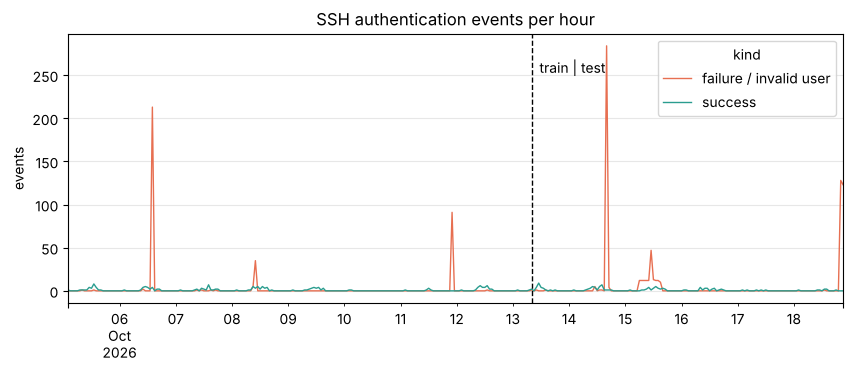

In [4]:
auth = events[events["event_type"].isin(["auth_success", "auth_failure", "invalid_user"])].copy()
auth["kind"] = np.where(auth["event_type"] == "auth_success", "success", "failure / invalid user")
hourly = auth.set_index("timestamp_utc").groupby("kind").resample("1h").size().unstack(0).fillna(0)

ax = hourly.plot(color={"success": "#2a9d8f", "failure / invalid user": "#e76f51"}, lw=1)
ax.axvline(result.cutoff, color="k", ls="--", lw=1)
ax.text(result.cutoff, ax.get_ylim()[1] * 0.9, "  train | test", va="top")
ax.set(title="SSH authentication events per hour", ylabel="events", xlabel="")
plt.show()

### 2.2 When do people log in?
Successful logins by hour of day (UTC). Normal activity clusters in working hours, plus a nightly spike at 02:00 from the `backup` service account. That spike is a reminder that "off-hours" is not the same as "suspicious".

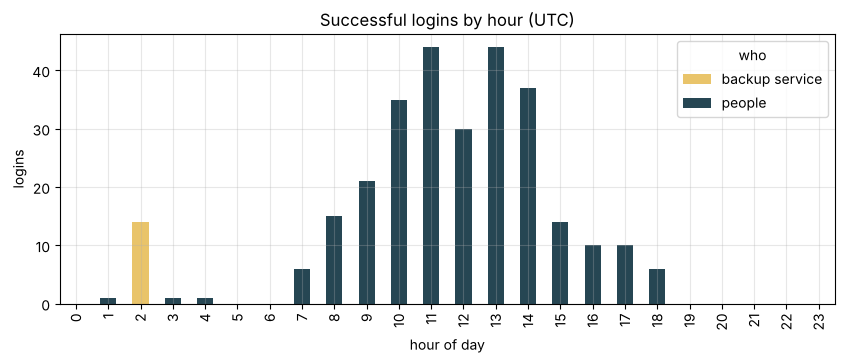

In [5]:
succ = auth[auth["kind"] == "success"].copy()
succ["hour"] = succ["timestamp_utc"].dt.hour
succ["who"] = np.where(succ["user"] == "backup", "backup service", "people")
succ.groupby(["hour", "who"]).size().unstack(fill_value=0).reindex(
    range(24), fill_value=0
).plot.bar(
    stacked=True,
    color={"people": "#264653", "backup service": "#e9c46a"},
    title="Successful logins by hour (UTC)",
)
plt.xlabel("hour of day")
plt.ylabel("logins")
plt.show()

### 2.3 Who is failing?
Source IPs by number of failed or invalid-user attempts. Most of the top sources are external (`203.0.113.x`), but **internal addresses appear too**: `10.0.5.20` is a monitoring account with a stale password, and the `10.0.1.x` addresses are office users who mistyped or forgot a password. All of these are benign. A detector that only counts failures will flag them.

In [6]:
fails = auth[auth["kind"] != "success"]
top = fails.groupby("src_ip").agg(
    failures=("line_no", "size"),
    distinct_users=("user", "nunique"),
    first=("timestamp_utc", "min"),
    last=("timestamp_utc", "max"),
)
top.sort_values("failures", ascending=False).head(10)

,failures,distinct_users,first,last
src_ip,,,,
203.0.113.62,288,6,2026-10-14 16:48:00+00:00,2026-10-14 17:00:09+00:00
203.0.113.114,251,6,2026-10-18 20:54:00+00:00,2026-10-18 21:06:26+00:00
203.0.113.10,213,6,2026-10-06 14:12:00+00:00,2026-10-06 14:20:58+00:00
10.0.5.20,118,1,2026-10-15 06:00:07+00:00,2026-10-15 15:45:11+00:00
203.0.113.49,91,6,2026-10-11 22:24:00+00:00,2026-10-11 22:27:50+00:00
203.0.113.23,35,14,2026-10-08 10:30:00+00:00,2026-10-08 10:58:59+00:00
203.0.113.75,35,16,2026-10-15 11:18:00+00:00,2026-10-15 11:47:32+00:00
10.0.1.21,7,1,2026-10-05 08:43:01+00:00,2026-10-14 11:11:16+00:00
10.0.1.20,5,1,2026-10-05 13:23:39+00:00,2026-10-08 09:14:06+00:00


## 3. Features: one row per (source IP, 10-minute window)

A single failed login means nothing. Forty in ten minutes is an attack. We aggregate events into windows and describe each with counts, ratios, sequence and history features. History features (`is_new_ip`, `n_new_user_ip_success`) only look backwards in time, so no information leaks from the future.

The table is very imbalanced, as real security data is. Almost all windows are normal.

In [7]:
from marlowe.features import MODEL_FEATURES

allw = pd.concat([result.train_windows.assign(split="train"), result.windows.assign(split="test")])
print(allw.groupby("split")["is_attack"].agg(windows="size", attack_windows="sum"))
allw[MODEL_FEATURES].describe().T[["mean", "50%", "max"]].round(2)

       windows  attack_windows
split                         
test       187              11
train      170               7


,mean,50%,max
n_events,3.77,1.00,239.00
n_failed,1.83,0.00,130.00
n_success,0.81,1.00,2.00
n_invalid_user,1.13,0.00,109.00
n_distinct_users,1.17,1.00,7.00
failure_ratio,0.24,0.00,1.00
success_after_failure,0.06,0.00,1.00
n_success_off_hours,0.05,0.00,1.00
n_new_user_ip_success,0.05,0.00,1.00
is_new_ip,0.06,0.00,1.00


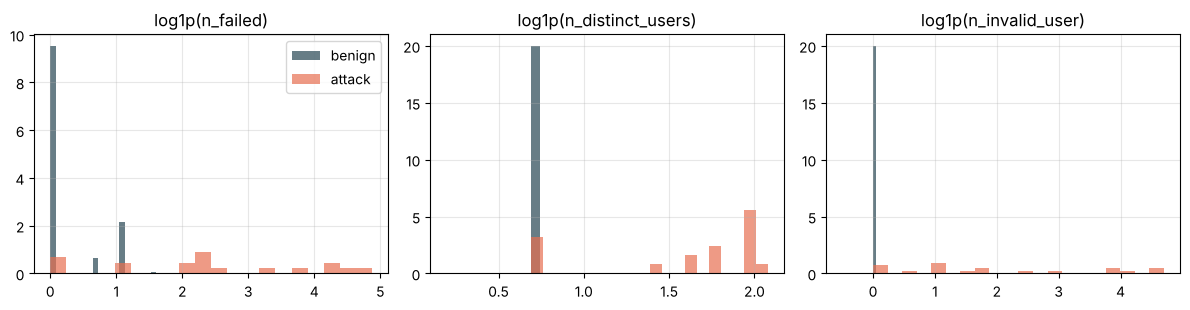

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, ["n_failed", "n_distinct_users", "n_invalid_user"], strict=True):
    for lab, colour in [(0, "#264653"), (1, "#e76f51")]:
        vals = np.log1p(allw.loc[allw["is_attack"] == lab, col])
        ax.hist(
            vals,
            bins=20,
            alpha=0.7,
            color=colour,
            label="attack" if lab else "benign",
            density=True,
        )
    ax.set(title=f"log1p({col})")
axes[0].legend()
plt.tight_layout()
plt.show()

Counts are heavily skewed, so they are `log1p`-transformed before modelling. The attack and benign distributions overlap at low counts. Slow attacks look like normal users within any one window.

## 4. Detection and evaluation

- **Rule baseline:** four readable rules with thresholds fixed in advance (see `marlowe/detection/rules.py`).
- **Isolation Forest:** unsupervised and trained *only on the training period*. Its flag threshold is the 98th percentile of training scores (`contamination=0.02`), chosen before evaluation.
- **Time-based split:** the first 60% of the timeline trains and the last 40% tests. A random split would let the model "see" future IPs and users and inflate the scores.

Accuracy would be meaningless here: flagging nothing at all would score about 94%. We report precision (how many flags are real), recall (how many attacks we catch), F1 and average precision (the area under the precision-recall curve, which does not depend on a threshold).

In [9]:
metrics = pd.DataFrame(result.metrics).T[
    ["precision", "recall", "f1", "tp", "fp", "fn", "average_precision"]
]
metrics.round(2)

,precision,recall,f1,tp,fp,fn,average_precision
rules,0.89,0.73,0.80,8.0,1.0,3.0,NaN
isolation_forest,1.00,0.45,0.62,5.0,0.0,6.0,0.96
either,0.90,0.82,0.86,9.0,1.0,2.0,NaN


### Incident-level view
Window recall understates usefulness. An investigator only needs *one* flagged window to start pulling a thread. Here is whether each test-period attack was caught by either detector.

In [10]:
result.incidents

,attack_id,n_windows,rules_flagged,rules_detected,if_flagged,if_detected,attack_type
0,A05,3,2,True,3,True,brute_force_success
1,A06,4,2,True,0,False,password_spray
2,A07,1,1,True,0,False,off_hours_compromise
3,A08,1,1,True,0,False,off_hours_compromise
4,A09,2,2,True,2,True,brute_force


### Precision-recall curve for the Isolation Forest
The curve shows the whole trade-off and not just one operating point. A high average precision with low recall at the chosen threshold means the **ranking** is good but the threshold is conservative.

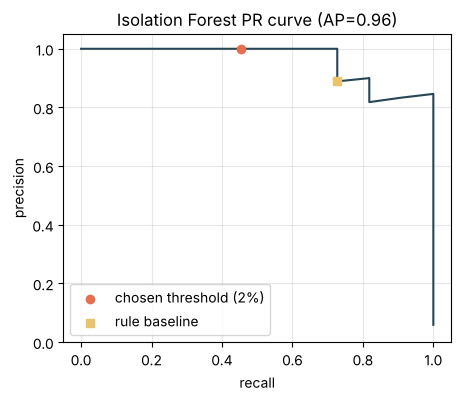

In [11]:
test = result.windows
p, r, _ = precision_recall_curve(test["is_attack"], test["if_score"])
op = result.metrics["isolation_forest"]
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(r, p, color="#264653")
ax.scatter(
    [op["recall"]], [op["precision"]], color="#e76f51", zorder=3, label="chosen threshold (2%)"
)
rb = result.metrics["rules"]
ax.scatter(
    [rb["recall"]], [rb["precision"]], marker="s", color="#e9c46a", zorder=3, label="rule baseline"
)
ax.set(
    xlabel="recall",
    ylabel="precision",
    title=f"Isolation Forest PR curve (AP={op['average_precision']:.2f})",
    ylim=(0, 1.05),
)
ax.legend(loc="lower left")
plt.show()

### Sensitivity analysis (diagnostic only)
How much does the threshold matter? This is computed on the test set, so it **must not** be used to pick the threshold. Doing that would be tuning on the test data. It shows how fragile the choice is.

In [12]:
rows = []
for c in [0.01, 0.02, 0.05, 0.10]:
    out = IsolationForestDetector(contamination=c).fit(result.train_windows).predict(test)
    rows.append({"contamination": c, **window_metrics(test["is_attack"], out["if_flag"])})
pd.DataFrame(rows).set_index("contamination")[
    ["precision", "recall", "f1", "tp", "fp", "fn"]
].round(2)

,precision,recall,f1,tp,fp,fn
contamination,,,,,,
0.01,1.0,0.36,0.53,4,0,7
0.02,1.0,0.45,0.62,5,0,6
0.05,0.9,0.82,0.86,9,1,2
0.10,0.2,1.00,0.33,11,44,0


## 5. Error analysis: read every mistake

Metrics tell you *how many*; only reading the cases tells you *why*. Every row links back to `line_nos` in the evidence.

In [13]:
cols = [
    "src_ip",
    "window_start",
    "n_failed",
    "n_success",
    "n_distinct_users",
    "rule_reasons",
    "if_score",
    "if_reasons",
    "attack_ids",
]
print("FALSE POSITIVES (flagged, but benign):")
display(test[(test["rule_flag"] | test["if_flag"]) & (test["is_attack"] == 0)][cols])
print("MISSED ATTACK WINDOWS (by both detectors):")
display(test[(test["is_attack"] == 1) & ~(test["rule_flag"] | test["if_flag"])][cols])

FALSE POSITIVES (flagged, but benign):


,src_ip,window_start,n_failed,n_success,n_distinct_users,rule_reasons,if_score,if_reasons,attack_ids
208,10.0.1.21,2026-10-14 11:10:00+00:00,4,1,1,a successful login after >= 3 failures from the same IP in a window,0.678976,,


MISSED ATTACK WINDOWS (by both detectors):


,src_ip,window_start,n_failed,n_success,n_distinct_users,rule_reasons,if_score,if_reasons,attack_ids
270,203.0.113.75,2026-10-15 11:10:00+00:00,2,0,1,,0.661710,,A06
272,203.0.113.75,2026-10-15 11:20:00+00:00,7,0,4,,0.681499,,A06


In [14]:
# Trace a finding to the evidence: the raw lines behind the top-ranked window.
top = result.findings().iloc[0]
n_lines = len(top["line_nos"])
print(f"{top['src_ip']} @ {top['window_start']}  (evidence {top['evidence_id']}, {n_lines} lines)")
print(events.set_index("line_no").loc[top["line_nos"][:5], "raw"].to_string())

203.0.113.62 @ 2026-10-14 16:50:00+00:00  (evidence 45d19d8f6137, 239 lines)
line_no
1309                    Oct 14 16:50:01 srv01 sshd[18052]: Invalid user oracle from 203.0.113.62 port 40168
1310    Oct 14 16:50:02 srv01 sshd[25971]: Failed password for invalid user oracle from 203.0.113.62 por...
1311          Oct 14 16:50:06 srv01 sshd[33890]: Failed password for root from 203.0.113.62 port 54189 ssh2
1312                    Oct 14 16:50:14 srv01 sshd[41809]: Invalid user oracle from 203.0.113.62 port 57658
1313    Oct 14 16:50:15 srv01 sshd[49728]: Failed password for invalid user oracle from 203.0.113.62 por...


## 6. Conclusions and limitations

**What we found**
- The rule baseline catches every test-period incident with one false positive (a user who forgot their password). On synthetic attacks *we designed*, rules written for those attack types are expected to do well. That is a known circularity, not proof that rules are enough.
- The Isolation Forest ranks windows very well (high average precision) but, at the pre-chosen 2% threshold, flags only the loudest windows. It raises no false positives but misses the quiet attacks. The sensitivity table shows performance changes sharply between 5% and 10%. At 10%, the monitoring account's steady failures flood the flags.
- Combining both detectors gives the best window recall. The two are complementary: rules explain *known* patterns, and the model ranks *unusual* ones.

**Limitations to keep in mind**
- **Synthetic data:** real "normal" behaviour is messier, and real attackers adapt. The next step is validation on a public dataset.
- **Small test set:** 11 attack windows across 5 incidents, so single errors move the metrics a lot. Treat the numbers as indicative.
- **Tumbling windows split attacks:** a brute force that ends with a successful login can put the success in a window *without* the failures. The `success_after_failures` rule then misses the most important line. Sliding windows, or a "failures from this IP in the last 30 minutes" feature, would fix this.
- **IP-centric only:** per-user behaviour (UEBA) features would help catch stolen credentials used from familiar networks.
- **An anomaly is a lead, not a conclusion.** Every flag here needs an analyst to confirm it against the raw lines.